<a href="https://colab.research.google.com/github/donjperpetua/ML_ENG_HW1/blob/main/ML_ENG_HW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Donald Perpetua | RIN: 662040925

Problem 1

In [2]:
from sklearn import datasets
import numpy as np
iris = datasets.load_iris()
iris.data
iris_features = iris.data[:, :4]
#defining 2 features from the original:
#sepal length + sepal width,
#petal length + petal width
X = np.array([
    iris_features[:, 0] + iris_features[:, 1],
    iris_features[:, 2] + iris_features[:, 1]
]).T
y = iris.target
X.shape
y.shape
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test=train_test_split(
    X,y,
    test_size=0.40,
    train_size=0.60,
    random_state=123,
    shuffle=True,
    stratify=y)
from sklearn import svm

clf = svm.SVC()
clf.fit(X_train, y_train)

preds = clf.predict(X_test)
print(preds)

print('actual iris species')
print(y_test)

from sklearn.metrics import accuracy_score
acc = accuracy_score(y_test,clf.predict(X_test) )
print('accuracy score :', acc)

[1 1 1 1 0 2 1 0 0 2 0 2 2 2 2 0 1 2 0 2 2 0 1 0 0 2 2 0 0 0 0 0 1 1 0 1 1
 2 0 1 0 2 2 2 0 2 2 1 0 0 1 1 2 1 2 1 1 2 1 2]
actual iris species
[1 1 1 1 0 1 2 0 0 2 0 2 2 1 2 0 1 2 0 2 2 0 1 0 0 2 1 0 0 0 0 0 1 2 0 1 1
 2 0 1 0 2 2 2 0 2 2 1 0 0 1 1 2 1 2 1 1 2 1 2]
accuracy score : 0.9166666666666666


Problem 2

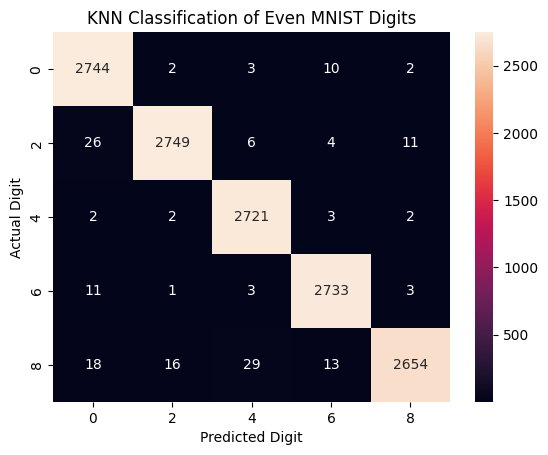

Correctly classified 6's: 2733


In [4]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

#load MNIST
mnist = fetch_openml('mnist_784', version=1, as_frame=False)

X = mnist.data
y = mnist.target.astype(int)

#keep only even digits
even_idx = y % 2 == 0

X = X[even_idx]
y = y[even_idx]

#split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.40,
    train_size=0.60,
    random_state=123,
    shuffle=True,
    stratify=y
)

#KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

#predictions
y_pred = knn.predict(X_test)

#confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 2, 4, 6, 8]
)
#Pair plot is best for low-dimensional problems. This problem has 784 features
#since each pixel is a feature.
#heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=[0, 2, 4, 6, 8],
    yticklabels=[0, 2, 4, 6, 8]
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("KNN Classification of Even MNIST Digits")
plt.show()

#correctly classified 6's
print("Correctly classified 6's:", cm[3, 3])

Problem 3

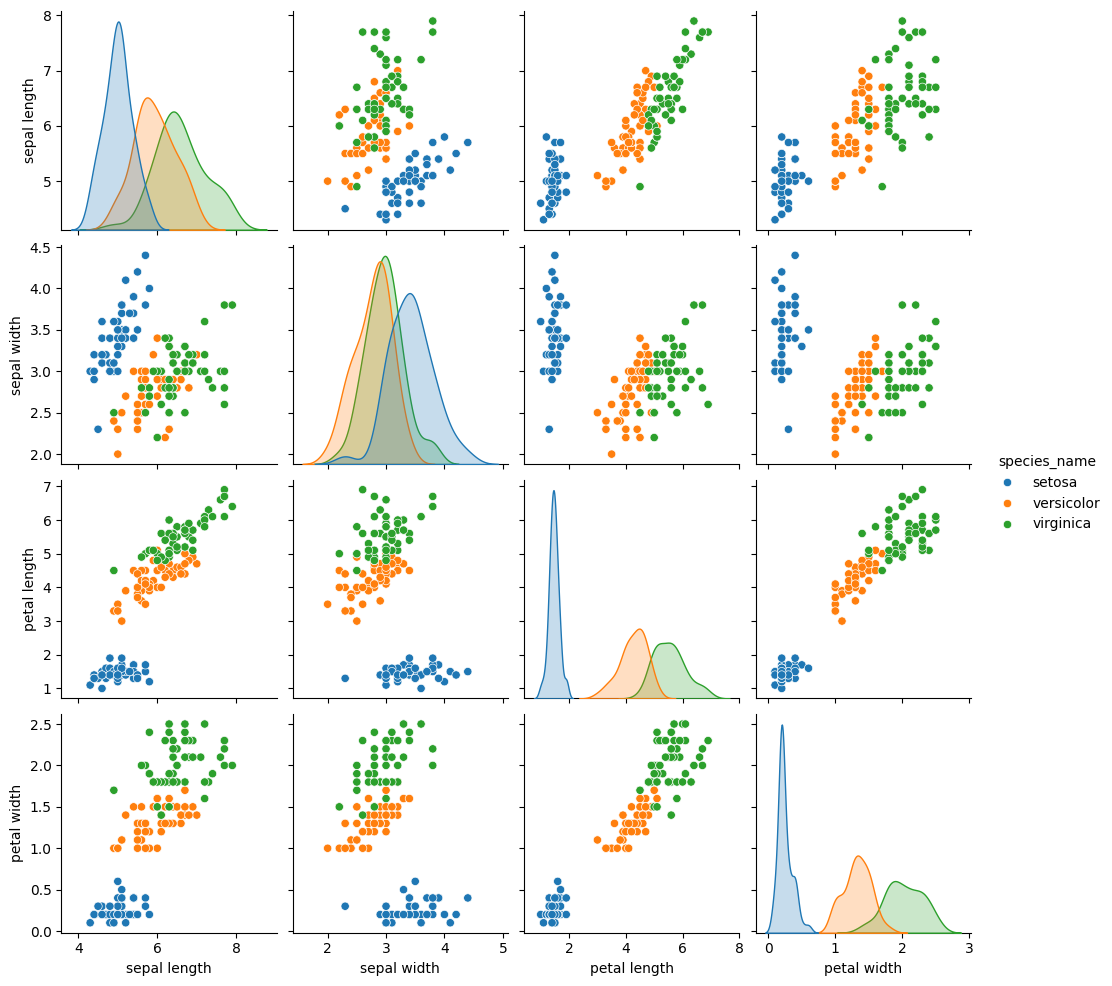

X_train shape: (105, 3)
X_test shape: (45, 3)
y_train shape: (105,)
y_test shape: (45,)


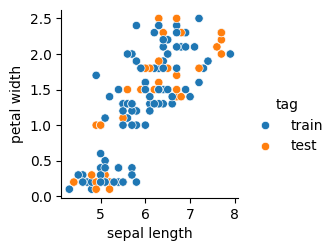

my K-Means labels:
[1 2 1 1 2 0 0 1 0 0 2 0 1 0 1 0 1 1 0 0 0 0 0 1 0 1 1 0 1 1 1 1 1 0 0 1 1
 1 1 0 2 0 1 2 1]
my K-Means centroids:
[[5.7 3.8 1.7]
 [6.5 3.  5.8]
 [7.2 3.6 6.1]]
my K-Means ARI: 0.452291212061099
Scikit-learn labels:
[2 1 2 1 1 0 0 2 0 0 1 0 1 0 2 0 2 2 0 0 0 0 0 2 0 2 1 0 1 1 1 1 2 2 2 2 2
 1 1 0 1 2 2 1 2]
Scikit-learn centroids:
[[5.04285714 3.43428571 1.48857143]
 [6.77857143 3.02857143 5.62142857]
 [5.82619048 2.72142857 4.35238095]]
Scikit-learn ARI: 0.6255022203425671


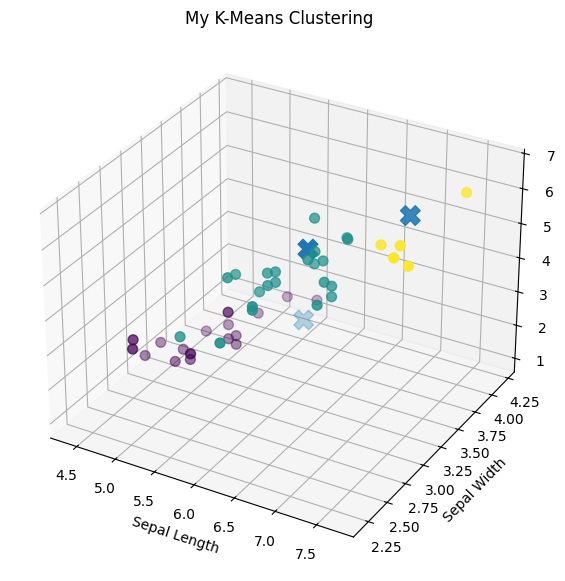

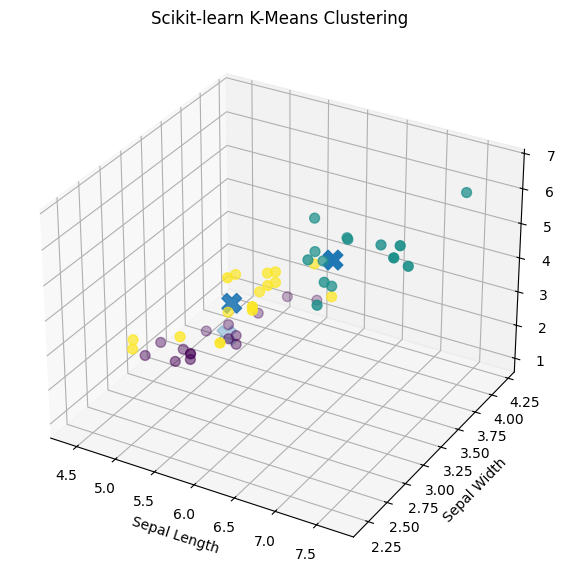

k = 2
My K-Means ARI: 0.47619047619047616
Scikit-learn ARI: 0.5279224277249057

k = 3
My K-Means ARI: 0.452291212061099
Scikit-learn ARI: 0.6255022203425671

k = 4
My K-Means ARI: 0.34060580385511546
Scikit-learn ARI: 0.580559841304827

k = 5
My K-Means ARI: 0.3250375455910749
Scikit-learn ARI: 0.5585874799357945



In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans as SKKMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(123)

data = load_iris()

df = pd.DataFrame()
df['sepal length'] = data['data'][:, 0]
df['sepal width'] = data['data'][:, 1]
df['petal length'] = data['data'][:, 2]
df['petal width'] = data['data'][:, 3]

df['target'] = data['target']

named_targets = []

for elm in df['target'].to_list():
    named_targets.append(data.target_names[elm])

df['species_name'] = named_targets

sns.pairplot(
    df.drop(labels=['target'], axis=1),
    hue='species_name'
)
plt.show()

X = df[['sepal length', 'sepal width', 'petal length']].to_numpy()
y = df['target'].to_numpy()

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X,
    y,
    range(X.shape[0]),
    test_size=0.30,
    train_size=0.70,
    random_state=123,
    shuffle=True,
    stratify=y
)

print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('y_train shape:', y_train.shape)
print('y_test shape:', y_test.shape)

tag = []

for i in range(X.shape[0]):
    if i in idx_train:
        tag.append('train')
    else:
        tag.append('test')

df['tag'] = tag

sns.pairplot(
    df.drop(labels=['target'], axis=1),
    x_vars=['sepal length'],
    y_vars=['petal width'],
    hue='tag'
)
plt.show()
#modified kmeans to implement Elkan's accelerated kmeans
#for more efficient learning
class KMeans:
    def __init__(self, k, max_iter=100):
        self.k = k
        self.max_iter = max_iter
        self.cluster_labels = None

    def fit(self, X):
        self.centroids = X[
            np.random.choice(
                X.shape[0],
                self.k,
                replace=False
            ),
            :
        ].copy()

        self.cluster_labels = np.arange(self.k)

        distances = np.array([
            np.linalg.norm(
                X - centroid,
                axis=1
            )
            for centroid in self.centroids
        ])

        self.clusters = np.argmin(
            distances,
            axis=0
        )

        upper_bounds = np.min(
            distances,
            axis=0
        )

        lower_bounds = distances.T.copy()

        for _ in range(self.max_iter):

            centroid_distances = np.array([
                [
                    np.linalg.norm(
                        self.centroids[i] -
                        self.centroids[j]
                    )
                    if i != j else np.inf
                    for j in range(self.k)
                ]
                for i in range(self.k)
            ])

            half_distances = (
                np.min(
                    centroid_distances,
                    axis=1
                ) / 2
            )

            new_clusters = self.clusters.copy()

            for i in range(X.shape[0]):

                current_cluster = self.clusters[i]

                if upper_bounds[i] <= half_distances[current_cluster]:
                    continue

                for j in range(self.k):

                    if j == current_cluster:
                        continue

                    if upper_bounds[i] <= lower_bounds[i, j]:
                        continue

                    if upper_bounds[i] <= (
                        centroid_distances[
                            current_cluster,
                            j
                        ] / 2
                    ):
                        continue

                    distance = np.linalg.norm(
                        X[i] -
                        self.centroids[j]
                    )

                    lower_bounds[i, j] = distance

                    if distance < upper_bounds[i]:
                        upper_bounds[i] = distance
                        current_cluster = j
                        new_clusters[i] = j

                lower_bounds[
                    i,
                    current_cluster
                ] = upper_bounds[i]

            if np.array_equal(
                new_clusters,
                self.clusters
            ):
                break

            self.clusters = new_clusters

            new_centroids = self.centroids.copy()

            for i in range(self.k):

                points = X[
                    self.clusters == i
                ]

                if len(points) > 0:
                    new_centroids[i] = points.mean(
                        axis=0
                    )

            centroid_movement = np.linalg.norm(
                new_centroids -
                self.centroids,
                axis=1
            )

            self.centroids = new_centroids

            upper_bounds += (
                centroid_movement[
                    self.clusters
                ]
            )

            lower_bounds = np.maximum(
                lower_bounds -
                centroid_movement,
                0
            )

        return self

    def predict(self, X):
        distances = np.array([
            np.linalg.norm(
                X - centroid,
                axis=1
            )
            for centroid in self.centroids
        ])

        return self.cluster_labels[
            np.argmin(
                distances,
                axis=0
            )
        ]

model = KMeans(k=3, max_iter=100)
model.fit(X_train)

kmeans_labels = model.predict(X_test)
cluster_coords = model.centroids

print('my K-Means labels:')
print(kmeans_labels)

print('my K-Means centroids:')
print(cluster_coords)

my_ari = adjusted_rand_score(
    y_test,
    kmeans_labels
)

print('my K-Means ARI:', my_ari)

sk_model = SKKMeans(
    n_clusters=3,
    random_state=123,
    n_init=10,
    algorithm='elkan'
)

sk_model.fit(X_train)

sk_labels = sk_model.predict(X_test)

print('Scikit-learn labels:')
print(sk_labels)

print('Scikit-learn centroids:')
print(sk_model.cluster_centers_)

sk_ari = adjusted_rand_score(
    y_test,
    sk_labels
)

print('Scikit-learn ARI:', sk_ari)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(
    111,
    projection='3d'
)

ax.scatter(
    X_test[:, 0],
    X_test[:, 1],
    X_test[:, 2],
    c=kmeans_labels,
    s=50
)

ax.scatter(
    cluster_coords[:, 0],
    cluster_coords[:, 1],
    cluster_coords[:, 2],
    marker='X',
    s=200
)

ax.set_xlabel('Sepal Length')
ax.set_ylabel('Sepal Width')
ax.set_zlabel('Petal Length')
ax.set_title('My K-Means Clustering')

plt.show()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(
    111,
    projection='3d'
)

ax.scatter(
    X_test[:, 0],
    X_test[:, 1],
    X_test[:, 2],
    c=sk_labels,
    s=50
)

ax.scatter(
    sk_model.cluster_centers_[:, 0],
    sk_model.cluster_centers_[:, 1],
    sk_model.cluster_centers_[:, 2],
    marker='X',
    s=200
)

ax.set_xlabel('Sepal Length')
ax.set_ylabel('Sepal Width')
ax.set_zlabel('Petal Length')
ax.set_title('Scikit-learn K-Means Clustering')

plt.show()

for k in [2, 3, 4, 5]:

    np.random.seed(123)

    model = KMeans(
        k=k,
        max_iter=100
    )

    model.fit(X_train)

    labels = model.predict(X_test)

    my_ari = adjusted_rand_score(
        y_test,
        labels
    )

    sk_model = SKKMeans(
        n_clusters=k,
        random_state=123,
        n_init=10,
        algorithm='elkan'
    )

    sk_model.fit(X_train)

    sk_labels = sk_model.predict(X_test)

    sk_ari = adjusted_rand_score(
        y_test,
        sk_labels
    )

    print('k =', k)
    print('My K-Means ARI:', my_ari)
    print('Scikit-learn ARI:', sk_ari)
    print()